In [1]:
import pandas as pd
import numpy as np
from datetime import datetime, timedelta

from sentinelhub import (
    SHConfig,
    SentinelHubRequest,
    DataCollection,
    BBox,
    CRS,
    MimeType,
    bbox_to_dimensions,
)

from pyproj import Transformer

LAI_V2 = DataCollection.define_byoc(
    # collection_id="03c8cc35-dff3-4446-9989-92d1e24287a7"
    collection_id="4046945c-968d-4411-882e-5842599613e5"
)


def get_lai_timeseries(
    lon,
    lat,
    start_date,
    end_date,
    config,
    buffer_m=500,
    resolution=300,
):

    # ---------------------------
    # bbox around point
    # ---------------------------
    to_3857 = Transformer.from_crs("EPSG:4326", "EPSG:3857", always_xy=True)
    to_4326 = Transformer.from_crs("EPSG:3857", "EPSG:4326", always_xy=True)

    x, y = to_3857.transform(lon, lat)

    bbox = BBox(
        [
            *to_4326.transform(x - buffer_m, y - buffer_m),
            *to_4326.transform(x + buffer_m, y + buffer_m),
        ],
        crs=CRS.WGS84,
    )

    size = bbox_to_dimensions(bbox, resolution=resolution)

    # ---------------------------
    # Modified evalscript based on JS version
    # ---------------------------
    evalscript = """
    //VERSION=3
    const factor = 0.0333333333;
    const offset = 0;

    function setup() {
      return {
        input: ["LAI", "dataMask"],
        output: [
          { id: "index", bands: 1, sampleType: "FLOAT32" }
        ],
        mosaicking: "SIMPLE"
      };
    }

    function evaluatePixel(samples) {
      // Apply the scaling factor directly during the request
      let val = samples.LAI * factor + offset;
      
      // If dataMask is 1, return the value, otherwise return NaN (nodata)
      const indexVal = samples.dataMask === 1 ? val : NaN;

      return {
        index: [indexVal]
      };
    }
    """

    start = datetime.fromisoformat(start_date)
    end = datetime.fromisoformat(end_date)

    dates = pd.date_range(start, end, freq="10D")

    out = []

    for d in dates:

        d2 = d + timedelta(days=10)

        request = SentinelHubRequest(
            evalscript=evalscript,
            input_data=[
                SentinelHubRequest.input_data(
                    data_collection=LAI_V2,
                    time_interval=(d.strftime("%Y-%m-%d"), d2.strftime("%Y-%m-%d")),
                )
            ],
            responses=[
                # Updated to match the "index" output id from our evalscript
                SentinelHubRequest.output_response("index", MimeType.TIFF)
            ],
            bbox=bbox,
            size=size,
            config=config,
        )

        try:
            # Data comes back as FLOAT32 already scaled with NaNs where dataMask was 0
            lai = request.get_data()[0].astype(float)

            # Calculate mean ignoring the NaN values natively mapped by our evalscript
            mean_val = np.nanmean(lai)

            # If the entire bounding box is NaN, np.nanmean returns NaN, which is safe to append
            out.append({
                "date": d,
                "lai_mean": mean_val,
            })

        except Exception as e:
            print("Failed", d, e)

    return pd.DataFrame(out)

In [2]:
import numpy as np
import pandas as pd
import geopandas as gpd
import os

from sentinelhub import SHConfig

# ----------------------------
# Load spatial data (gpkg)
# ----------------------------
loc_gdf = gpd.read_file("location.gpkg")

# ----------------------------
# Sentinel Hub config
# ----------------------------
config = SHConfig()
config.sh_client_id = "sh-d43c4a0d-222d-4485-bfd6-9ca8ef436c5b"
config.sh_client_secret = "qept9sWIGD5ZOs2yGI4wsfnj7o8SmaSf"
config.sh_base_url = "https://sh.dataspace.copernicus.eu"
config.sh_token_url = (
    "https://identity.dataspace.copernicus.eu/"
    "auth/realms/CDSE/protocol/openid-connect/token"
)

# ----------------------------
# Output directory
# ----------------------------
out_dir = "lai_outputs"
os.makedirs(out_dir, exist_ok=True)

for _, row in loc_gdf.iterrows():
    # geometry coordinates
    lon = row.geometry.x
    lat = row.geometry.y

    # index from site.csv (adjust column name if different)
    idx = row["location"] if "location" in row else row.name

    print(f"Processing {idx} at ({lon}, {lat})")

    df = get_lai_timeseries(
        lon=lon,
        lat=lat,
        start_date="2020-01-01",
        end_date="2021-12-31",
        config=config,
        buffer_m=300
    )

    out_path = os.path.join(out_dir, f"LAI_{idx}.csv")
    df.to_csv(out_path, index=False)

Processing 0 at (11.684572155481815, 53.21992654609531)


/tmp/ipykernel_683554/1145992618.py:115: RuntimeWarning: Mean of empty slice
  mean_val = np.nanmean(lai)


Processing 1 at (14.00095395952878, 53.06624690115396)
Processing 2 at (13.150556152985098, 53.01280281687521)


/tmp/ipykernel_683554/1145992618.py:115: RuntimeWarning: Mean of empty slice
  mean_val = np.nanmean(lai)


Processing 3 at (13.984083840787296, 52.88354741490191)
Processing 4 at (12.510115906472222, 52.82808362021714)
Processing 5 at (14.3033633979962, 52.634100975602266)
Processing 6 at (12.737611575627787, 52.609551852717644)
Processing 7 at (12.756725532467426, 52.45904076346073)
Processing 8 at (13.0209766912736, 52.40038559039733)
Processing 9 at (13.442123869143886, 52.39972652682418)
Processing 10 at (13.78780782572379, 52.360386171507216)
Processing 11 at (14.502050489316913, 52.350036810978786)
Processing 12 at (12.53191732474632, 52.35265129311424)
Processing 13 at (13.200047868509023, 52.31075508290191)
Processing 14 at (14.704604878341298, 51.97280530221617)
Processing 15 at (14.447455690647772, 51.784219363632694)
Processing 16 at (13.82542300396909, 51.725006185649136)
Processing 17 at (13.886265241002942, 51.632299479255856)


<Axes: xlabel='date'>

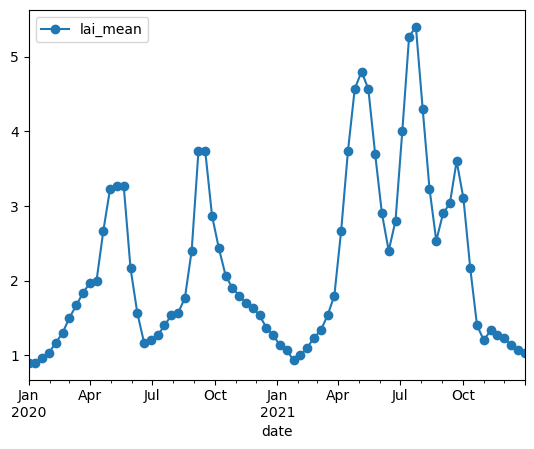

In [3]:
df.set_index("date").plot(y="lai_mean", marker="o")